Name: Anirudh Kavle
<br>
Github Username: Anirudh-Kavle
<br>
Email: kavle@usc.edu
<br>
USC ID: 6327535963

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

Question 1 was submitted with Task 3. Its loading, splitting and feature-extraction code is repeated here because Question 2 builds on it.

### (a) Obtain Data

Import packages

In [1]:
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_auc_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", message="The least populated class")   # expected for bending2, see the folds cell
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
SEED = 42

Get the AReM Data Set

The data is in `../data/AReM`: one folder per activity, 7 folders and 88 CSV files in total. Each file is one instance, with a `time` column (a reading every 250 ms) and 6 time series: `avg_rss12, var_rss12, avg_rss13, var_rss13, avg_rss23, var_rss23`. Below, these are series 1 to 6 in that order. Every file starts with 5 comment lines beginning with `#`.

Files are sorted by activity, then by dataset number (as numbers, so `dataset10` comes after `dataset9`).

In [2]:
DATA_DIR = Path("../data/AReM")
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def dataset_number(path):
    return int(path.stem.removeprefix("dataset"))

def load_instance(path):
    # values may be separated by commas or spaces; usecols drops the empty field left by a trailing comma
    return pd.read_csv(path, comment="#", header=None, names=["time"] + SERIES,
                       sep=r"[,\s]+", engine="python", usecols=range(7))

files = [f for act in ACTIVITIES for f in sorted((DATA_DIR / act).glob("dataset*.csv"), key=dataset_number)]
assert len(files) == 88, f"expected 88 files in {DATA_DIR}, found {len(files)}"
instances = [load_instance(f) for f in files]
series = [df[SERIES].to_numpy() for df in instances]
meta = pd.DataFrame({"activity": [f.parent.name for f in files],
                     "dataset": [dataset_number(f) for f in files],
                     "readings": [len(df) for df in instances]},
                    index=pd.RangeIndex(1, len(files) + 1, name="Instance"))

assert not any(df.isna().any().any() for df in instances)
print(len(files), "files loaded")
print("readings per instance:", meta.readings.value_counts().to_dict())

88 files loaded
readings per instance: {480: 87, 479: 1}


Data cleaning: the check below goes through the raw text of every file, looking for formatting problems and for missing readings (each file should have one reading every 250 ms from 0 to 119,750 ms).

In [3]:
expected_times = set(range(0, 120_000, 250))
audit = []
for f, df in zip(files, instances):
    lines = [ln for ln in f.read_text().splitlines() if ln and not ln.startswith("#")]
    name = f"{f.parent.name}/{f.name}"
    if not all("," in ln for ln in lines):
        audit.append((name, "values separated by spaces, not commas"))
    n_trailing = sum(ln.rstrip().endswith(",") for ln in lines)
    if n_trailing:
        audit.append((name, f"lines ending in a comma: {n_trailing}"))
    missing = sorted(expected_times - set(df.time))
    if missing:
        audit.append((name, f"{len(df)} readings, missing {missing} ms"))
pd.DataFrame(audit, columns=["file", "problem"])

,file,problem
0,bending2/dataset4.csv,"values separated by spaces, not commas"
1,cycling/dataset9.csv,lines ending in a comma: 1
2,cycling/dataset14.csv,lines ending in a comma: 1
3,sitting/dataset8.csv,"479 readings, missing [13500] ms"


None of the input files were edited. Each problem is handled while the file is read:

- `bending2/dataset4.csv`: values are separated by spaces. The parser accepts commas or spaces, so the values are read unchanged.
- `cycling/dataset9.csv` and `cycling/dataset14.csv`: the last line (time 119,750 ms) ends with a comma, which creates an empty 8th field. Only the first 7 fields are kept.
- `sitting/dataset8.csv`: the reading at 13,500 ms is missing, so the file has 479 readings instead of 480. I didn't fill in a value. All features are computed from the 479 readings that are there, and none of them needs evenly spaced readings.

Some files are byte-for-byte copies of each other:

In [4]:
meta["md5"] = [hashlib.md5(f.read_bytes()).hexdigest() for f in files]
names = meta.activity + "/dataset" + meta.dataset.astype(str)
(meta.assign(file=names)[meta.md5.duplicated(keep=False)]
     .groupby("md5").file.agg(" = ".join).reset_index(drop=True).to_frame("identical files"))

,identical files
0,lying/dataset1 = lying/dataset15
1,lying/dataset9 = lying/dataset14
2,lying/dataset5 = lying/dataset12
3,lying/dataset7 = lying/dataset13
4,lying/dataset3 = lying/dataset11
5,cycling/dataset1 = cycling/dataset15


Six pairs of files are identical, so the 88 instances contain at most 82 distinct recordings. All 88 are kept, since the task defines the dataset as 88 instances. Question 2 uses the file hash to keep both copies of a pair in the same cross-validation fold.

### (b) Splitting Data

Test data: datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2 and 3 in every other folder. All other datasets are training data.

For the binary problems in 2(a) and 2(b), the label is 1 for bending (`bending1` or `bending2`) and 0 for every other activity. 2(c) uses the activity itself as the label.

In [5]:
test_cutoff = np.where(meta.activity.str.startswith("bending"), 2, 3)
meta["split"] = np.where(meta.dataset <= test_cutoff, "test", "train")
train, test = (meta.split == "train").to_numpy(), (meta.split == "test").to_numpy()
y_bin = meta.activity.str.startswith("bending").astype(int).to_numpy()
y_multi = meta.activity.to_numpy()
pd.crosstab(meta.activity, meta.split, margins=True, margins_name="Total")[["train", "test", "Total"]]

split,train,test,Total
activity,,,
bending1,5,2,7
bending2,4,2,6
cycling,12,3,15
lying,12,3,15
sitting,12,3,15
standing,12,3,15
walking,12,3,15
Total,69,19,88


### (c) Feature Extraction

1(c)i and iii were answered in Task 3. The 1(c)ii features are recomputed below with one function, `make_features(l, stats)`, which Question 2 also uses. It cuts each instance's readings into `l` consecutive pieces with `np.array_split` (piece lengths differ by at most one reading, which also handles the 479-reading file) and computes each statistic for each of the 6 series in each piece. Standard deviation is the sample SD (divisor $n-1$); quartiles use linear interpolation between readings.

Columns are named `stat_j` for whole series, e.g. `q1_6` is the first quartile of series 6 (1st quart$_6$ in the handout), and `stat_j_partk` for piece `k` once a series is split.

For 1(c)iv, Task 3 selected mean, standard deviation and maximum, and Question 2 uses those three throughout.

In [6]:
STAT_FUNCS = {"min": np.min, "max": np.max, "mean": np.mean, "median": np.median,
              "std": lambda s: s.std(ddof=1),
              "q1": lambda s: np.percentile(s, 25), "q3": lambda s: np.percentile(s, 75)}
SELECTED = ["mean", "std", "max"]       # the three features chosen in 1(c)iv

def make_features(l, stats=SELECTED):
    rows = []
    for x in series:
        row = {}
        for k, piece in enumerate(np.array_split(x, l), start=1):
            for j in range(6):
                for stat in stats:
                    row[f"{stat}_{j + 1}" + (f"_part{k}" if l > 1 else "")] = STAT_FUNCS[stat](piece[:, j])
        rows.append(row)
    return pd.DataFrame(rows, index=meta.index)

features_1c = make_features(1, list(STAT_FUNCS))
print(features_1c.shape[0], "instances x", features_1c.shape[1], "features")
meta[["activity", "dataset", "split"]].join(features_1c).round(3)

88 instances x 42 features


,activity,dataset,split,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.625,40.500,1.477,39.250,42.000,0.0,1.30,0.359,0.430,0.323,0.000,0.500,4.00,29.50,19.041,19.250,4.463,16.000,23.250,0.0,7.23,0.833,0.500,0.966,0.000,1.120,27.25,38.25,34.311,35.000,2.188,33.000,36.000,0.00,1.92,0.571,0.430,0.583,0.000,1.300
2,bending1,2,test,38.00,45.67,42.813,42.500,1.436,42.000,43.670,0.0,1.22,0.372,0.470,0.289,0.000,0.500,2.00,29.50,20.097,21.000,3.894,19.000,22.250,0.0,5.76,0.876,0.500,1.047,0.000,1.145,27.67,38.50,33.025,33.000,1.995,32.000,34.500,0.00,3.11,0.571,0.430,0.601,0.000,1.300
3,bending1,3,train,35.00,47.40,43.954,44.330,1.559,43.000,45.000,0.0,1.70,0.426,0.470,0.339,0.000,0.500,6.50,29.75,22.122,23.000,3.031,19.750,24.000,0.0,4.44,0.497,0.430,0.551,0.000,0.830,29.00,38.50,35.588,36.000,2.000,35.362,36.500,0.00,1.79,0.493,0.430,0.514,0.000,0.940
4,bending1,4,train,33.00,47.75,42.180,43.500,3.671,39.150,45.000,0.0,3.00,0.696,0.500,0.631,0.000,1.120,8.50,30.00,22.184,23.000,3.810,20.500,24.372,0.0,5.15,0.990,0.830,0.954,0.430,1.300,20.00,38.67,33.494,35.000,3.849,30.458,36.330,0.00,2.18,0.614,0.500,0.524,0.000,1.000
5,bending1,5,train,33.00,45.75,41.678,41.750,2.243,41.330,42.750,0.0,2.83,0.536,0.500,0.405,0.430,0.710,3.00,28.25,19.007,19.125,4.087,16.500,22.062,0.0,6.42,0.842,0.500,0.929,0.430,1.120,23.67,37.50,29.857,30.000,2.411,28.458,31.250,0.00,1.79,0.383,0.430,0.389,0.000,0.500
6,bending1,6,train,37.00,48.00,43.455,43.250,1.386,42.500,45.000,0.0,1.58,0.378,0.470,0.316,0.000,0.500,5.75,27.00,15.793,15.000,3.848,13.000,18.270,0.0,10.03,0.849,0.500,0.996,0.430,1.120,8.00,33.50,23.035,23.500,2.489,22.250,24.000,0.00,5.26,0.680,0.500,0.623,0.430,0.870
7,bending1,7,train,36.25,48.00,43.969,44.500,1.618,43.310,44.670,0.0,1.50,0.413,0.470,0.263,0.430,0.500,1.50,26.33,15.868,16.250,3.742,14.250,18.000,0.0,5.17,0.666,0.470,0.789,0.000,0.940,11.33,30.75,22.104,21.670,3.318,20.500,23.750,0.00,2.96,0.555,0.490,0.488,0.000,0.830
8,bending2,1,test,12.75,51.00,24.563,24.250,3.738,23.188,26.500,0.0,6.87,0.591,0.430,0.837,0.000,0.710,0.00,25.33,19.121,20.250,4.300,18.000,22.000,0.0,6.76,0.737,0.470,0.927,0.000,0.870,10.67,30.00,23.493,23.750,3.694,20.500,27.000,0.00,4.97,0.700,0.500,0.694,0.430,0.870
9,bending2,2,test,0.00,42.75,27.465,28.000,3.584,25.500,30.000,0.0,7.76,0.450,0.430,0.767,0.000,0.500,7.50,35.00,20.843,20.750,3.826,18.000,22.500,0.0,5.76,0.780,0.500,0.904,0.000,0.940,0.00,33.00,17.618,18.000,5.054,15.000,20.750,0.00,6.76,1.122,0.830,1.012,0.470,1.300


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

These choices apply to every part of Question 2:

- Features: mean, std and max of every piece of every series, so an instance split into `l` pieces has $18\,l$ features (18 at $l=1$, 360 at $l=20$). Splitting never adds rows: one instance stays one row, and only the number of columns grows.
- Cross-validation: one fixed set of 5 folds, reused for every setting, so all settings are compared on the same splits. The folds are stratified, because only 9 of the 69 training instances are bending and an unstratified fold could get none. They're also grouped by file hash, so the two copies of an identical file (found in 1(a)) always land in the same fold and no instance is validated against its own copy.
- Anything learned from the data (scaling, feature selection, bin edges) is fit on the training folds only.

In [7]:
FEATURES = {l: make_features(l) for l in range(1, 21)}
groups = meta.md5.to_numpy()[train]
folds_bin = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
                 .split(np.zeros(train.sum()), y_bin[train], groups))
folds_multi = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
                   .split(np.zeros(train.sum()), y_multi[train], groups))
print("features per instance:", {l: FEATURES[l].shape[1] for l in (1, 2, 10, 20)})
print("bending instances per validation fold:", [int(y_bin[train][v].sum()) for _, v in folds_bin])

features per instance: {1: 18, 2: 36, 10: 180, 20: 360}
bending instances per validation fold: [2, 2, 1, 2, 2]


In the 7-class folds used in 2(c), `bending2` has only 4 training instances, so one of the 5 validation folds has no `bending2`. scikit-learn warns about this. It's expected, so the first cell filters that warning.

### (a) Binary Classification Using Logistic Regression

#### i. Plots

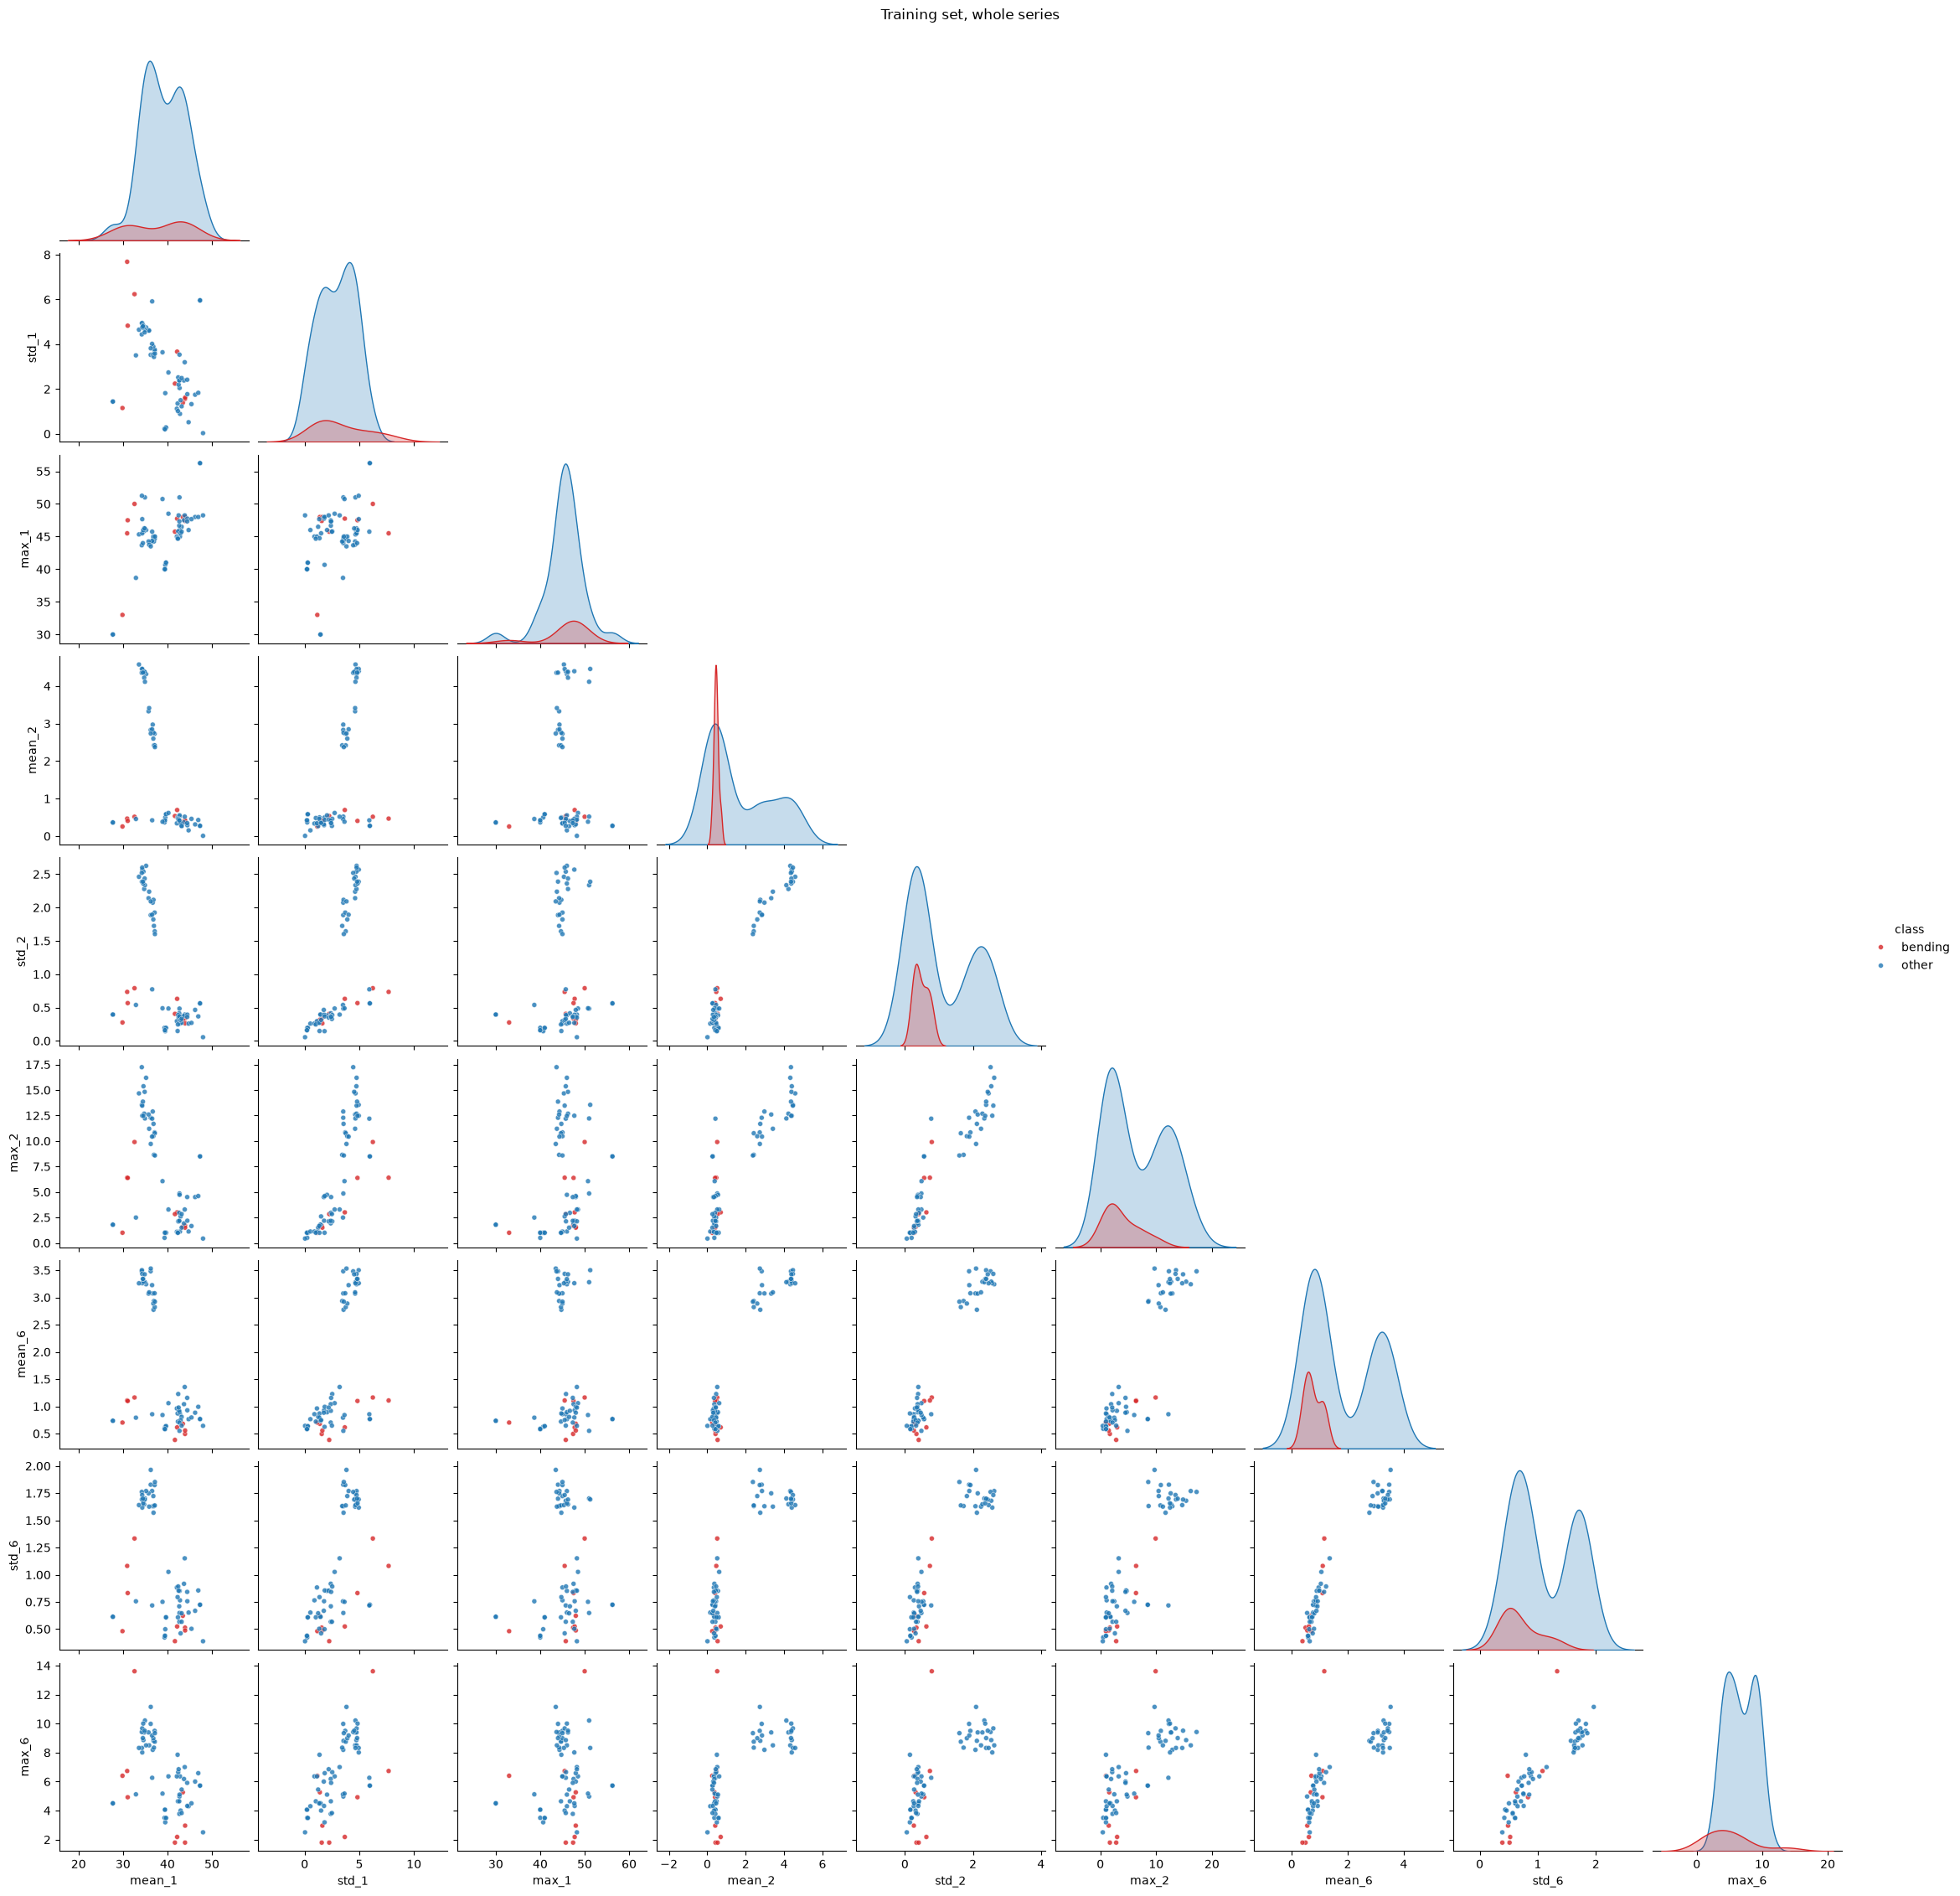

In [8]:
def scatter(l, part=1):
    suffix = f"_part{part}" if l > 1 else ""
    cols = [f"{stat}_{j}{suffix}" for j in (1, 2, 6) for stat in SELECTED]
    df = FEATURES[l].loc[train, cols].rename(columns=lambda c: c.removesuffix(suffix))
    df["class"] = np.where(y_bin[train] == 1, "bending", "other")
    g = sns.pairplot(df, hue="class", corner=True, plot_kws={"s": 18, "alpha": 0.8},
                     palette={"bending": "tab:red", "other": "tab:blue"})
    g.figure.suptitle("Training set, " + ("whole series" if l == 1 else f"part {part} of 2"), y=1.01)
    plt.show()

scatter(1)

- The training instances fall into two groups. The split is clearest in the features of series 2 and 6 (`var_rss12`, `var_rss23`): `mean_2`, `std_2`, `mean_6` and `std_6` each have a low group and a high group with a clear gap between them. The high group contains only other activities.
- Every bending instance is in the low group. Inside that group the red points overlap the blue ones in every panel, so no pair of these features separates bending from the other activities.
- The bending points themselves form two clusters in `mean_1`, around 30 to 33 and around 42 to 44, and each cluster sits among blue points.

#### ii. Splitted Plots

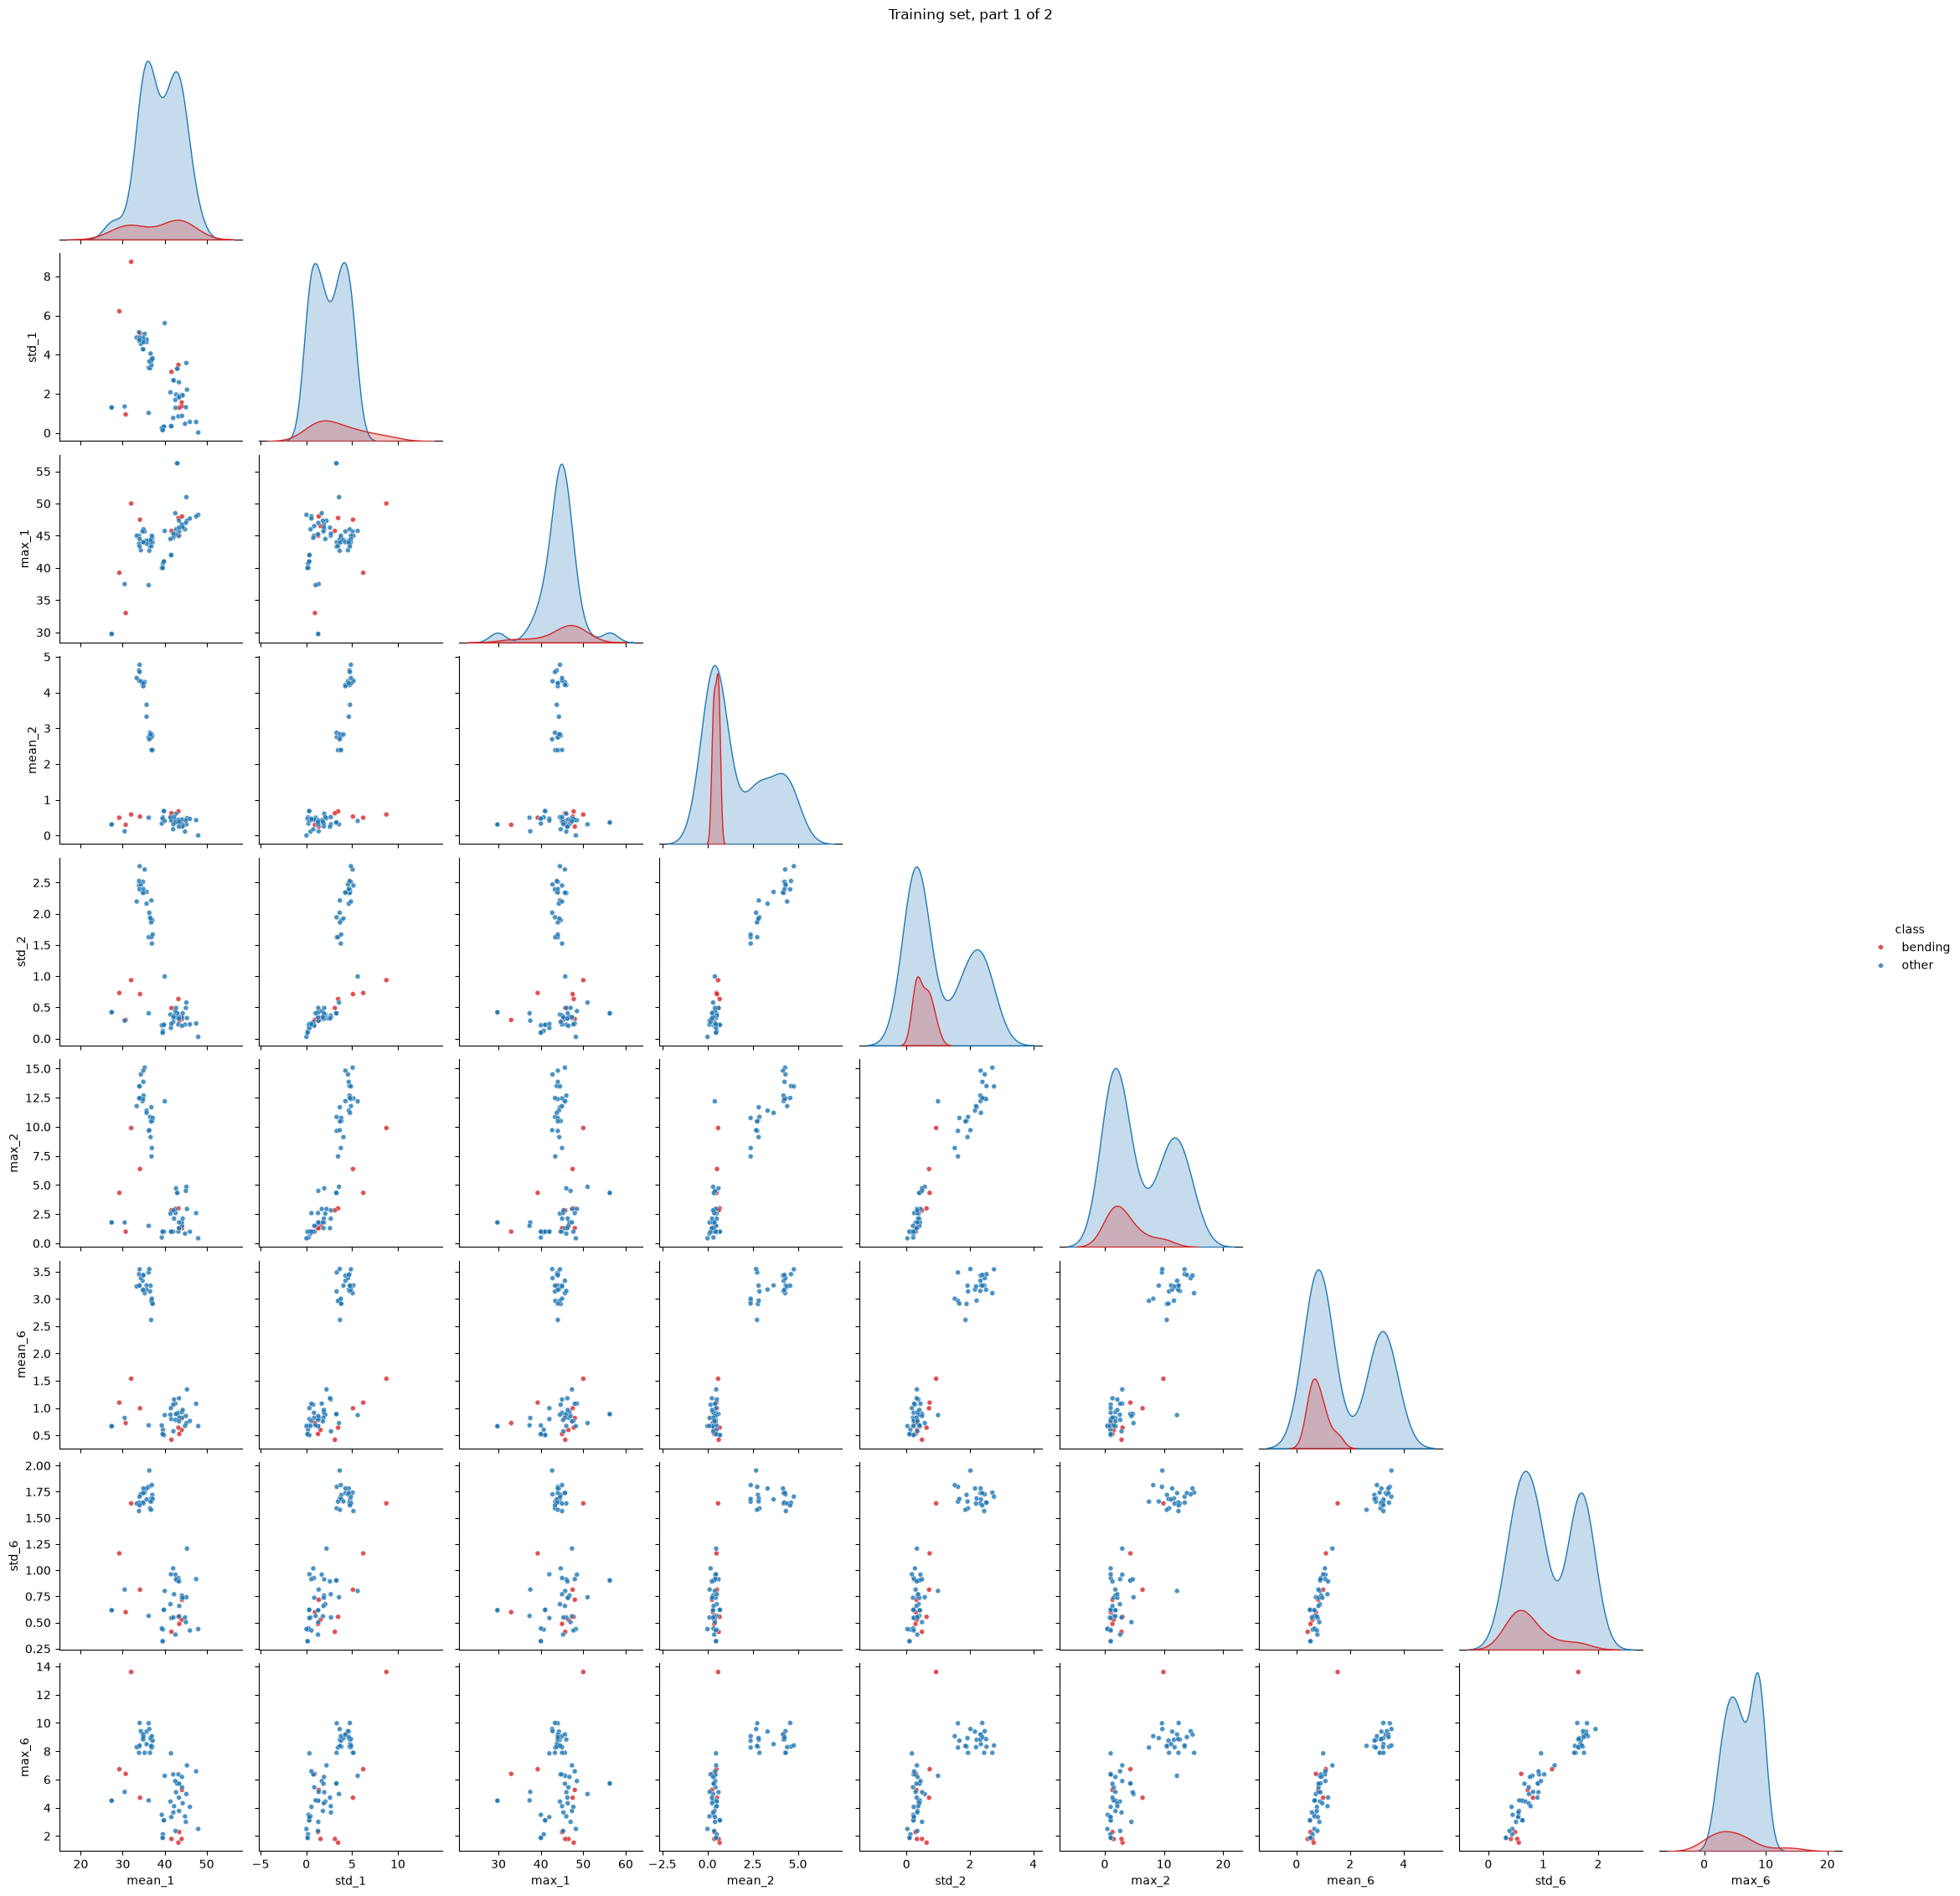

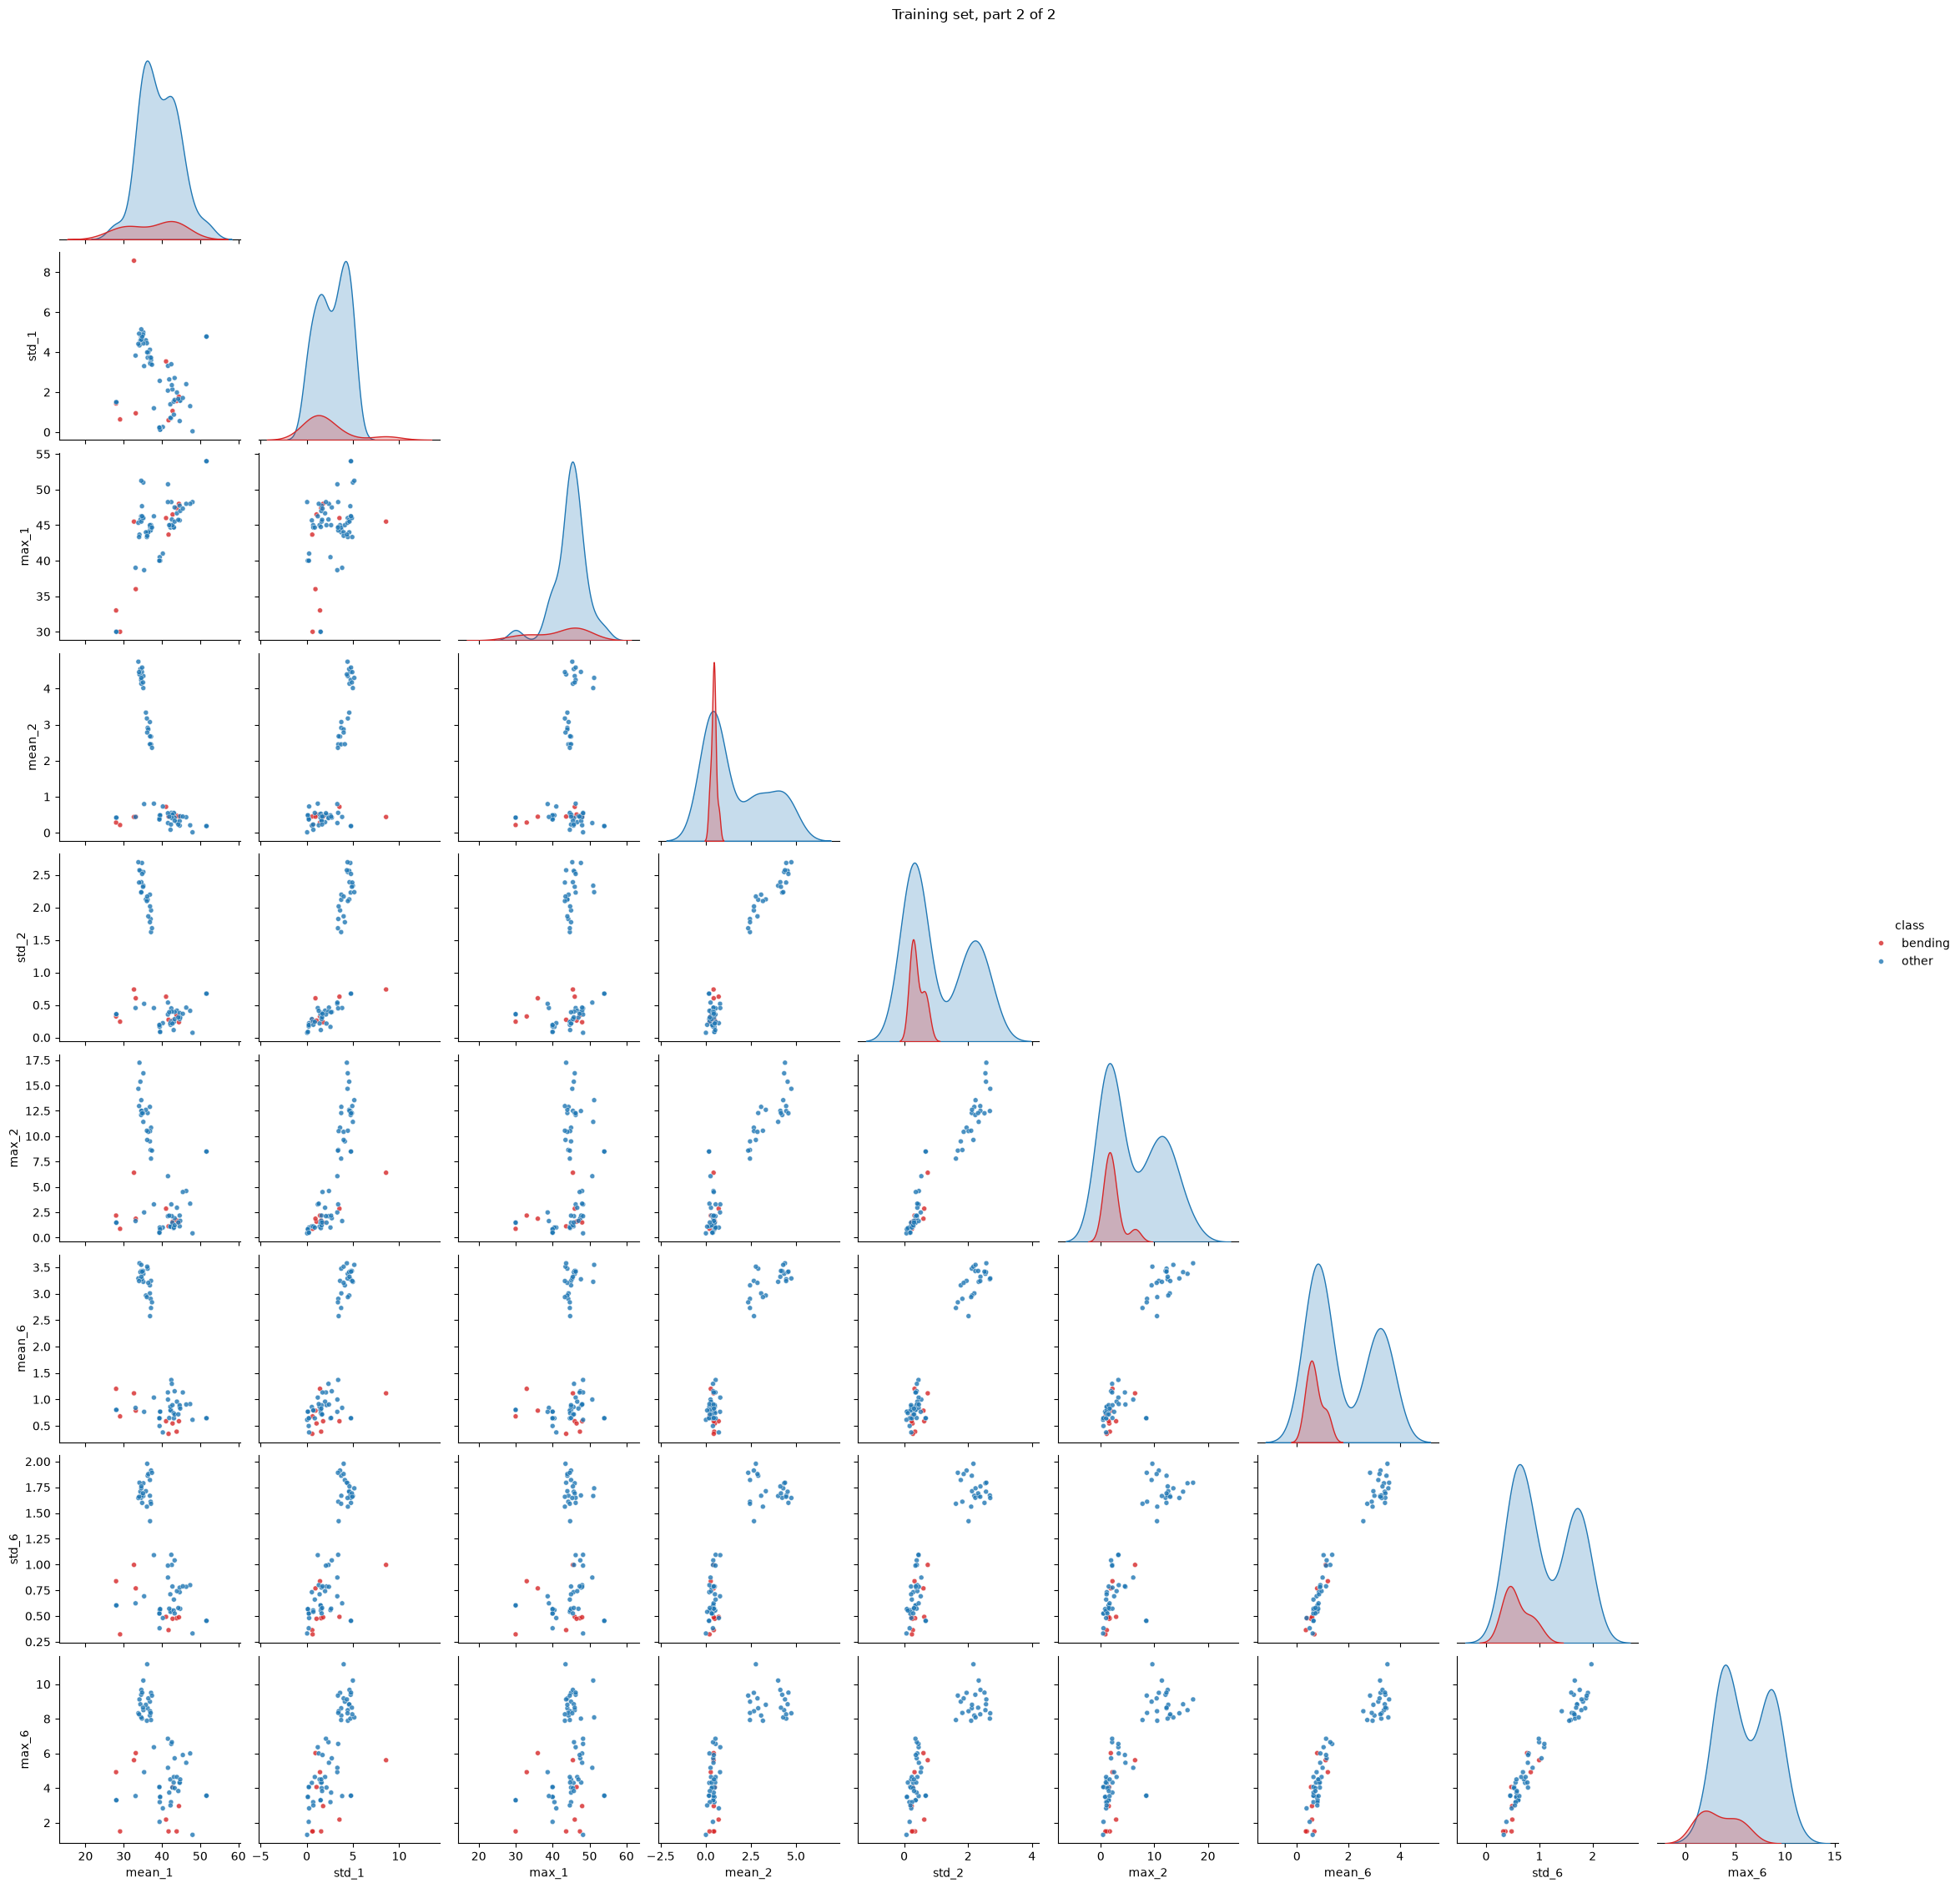

In [9]:
scatter(2, 1)
scatter(2, 2)

**No considerable difference.** Both halves show the same two groups as the whole series, and in both halves bending again overlaps the other low-group instances in every panel. The only visible change: in the first half one bending instance has `std_6` of about 1.6, inside the high group; in the second half it is back in the low group.

#### iii. Time Series Segments

I use logistic regression with no penalty (C = $10^6$, footnote 3) together with Recursive Feature Elimination (RFE), the backward-selection option the handout allows. I don't prune by p-values: the training classes are linearly separable (see vi), and that makes the p-values meaningless.

For each $l = 1, \dots, 20$ and each of the 5 folds:

1. fit the scaler on the 4 training folds and apply it to the held-out fold;
2. run RFE on the 4 training folds all the way down to 1 feature, one feature at a time; its ranking gives the top $p$ features for every $p$;
3. for $p = 1, \dots, 20$, fit logistic regression on the top $p$ features of the training folds and score it on the held-out fold.

The pair $(l, p)$ with the highest mean held-out accuracy wins. Ties go to the smaller $l$, then the smaller $p$ (the simpler model). The search stops at $p = 20$ (18 at $l = 1$, which only has 18 features).

The right and wrong ways to cross-validate here differ in where the feature selection happens.

The wrong way is to run RFE (or p-value pruning) once on all 69 training instances, then cross-validate only the final logistic regression on the features it picked. The held-out folds have then already helped choose those features, so the CV accuracy comes out too high. With 69 instances and up to 360 features, some feature will separate bending by chance, and nothing in this setup would catch it.

The right way, which is what I do, repeats everything that learns from the data inside each training fold: the scaler, RFE and the logistic regression fit. The held-out fold is only used for scoring, so a feature that separated bending by chance in the training folds stops working on the held-out fold, and the CV accuracy shows it. $l$ is picked the same way, because every candidate $l$ goes through the same folds. Picking $l$ or $p$ by looking at the test set would be the same kind of mistake as the wrong way above.

In [10]:
def lr():
    return LogisticRegression(C=1e6, max_iter=1000)    # C -> large removes the L2 penalty


def best_row(cv, key):
    # ties go to the smaller l, then the smaller key: the simpler model
    return next(cv.sort_values(["cv_acc", "l", key], ascending=[False, True, True]).itertuples(index=False))


rfe_rows = []
for l in range(1, 21):
    X, y = FEATURES[l].to_numpy()[train], y_bin[train]
    p_max = min(X.shape[1], 20)
    acc = np.zeros((len(folds_bin), p_max))
    for f, (fit_idx, val_idx) in enumerate(folds_bin):
        scaler = StandardScaler().fit(X[fit_idx])
        Z_fit, Z_val = scaler.transform(X[fit_idx]), scaler.transform(X[val_idx])
        rank = RFE(lr(), n_features_to_select=1, step=1).fit(Z_fit, y[fit_idx]).ranking_
        for p in range(1, p_max + 1):
            keep = rank <= p
            acc[f, p - 1] = accuracy_score(y[val_idx], lr().fit(Z_fit[:, keep], y[fit_idx]).predict(Z_val[:, keep]))
    rfe_rows += [(l, p, acc[:, p - 1].mean()) for p in range(1, p_max + 1)]
rfe_cv = pd.DataFrame(rfe_rows, columns=["l", "p", "cv_acc"])

L_RFE, P_RFE, CV_RFE = best_row(rfe_cv, "p")
print(f"best (l, p) = ({L_RFE}, {P_RFE}), CV accuracy {CV_RFE:.4f}\n")
print("best p for each l:")
print(rfe_cv.loc[rfe_cv.groupby("l").cv_acc.idxmax()].round(4).to_string(index=False))

best (l, p) = (11, 4), CV accuracy 0.9846

best p for each l:
 l  p  cv_acc
 1  4  0.9429
 2 10  0.9121
 3 11  0.9560
 4  2  0.9560
 5 12  0.9132
 6  7  0.9418
 7  6  0.9275
 8  1  0.9132
 9  6  0.9418
10 19  0.9571
11  4  0.9846
12 20  0.9571
13  6  0.9560
14  4  0.9418
15 14  0.9418
16  3  0.9560
17 19  0.9571
18  9  0.9703
19  7  0.9703
20  3  0.9703


CV picks **(l, p) = (11, 4)**, with accuracy 0.985. The peak is narrow, though: l = 10 and l = 12 only reach 0.957. Each validation fold holds about 14 instances, so one misclassified held-out instance moves the mean CV accuracy by about 1.4 points. So most rows of the table differ by one or two instances, and there's no steady trend in l. Splitting more finely neither clearly helps nor clearly hurts.

#### iv. Confusion Matrix

The final model refits the scaler, RFE and logistic regression on all 69 training instances with the selected $(l, p)$. Standard errors come from the inverse of the Fisher information $X^\top W X$, with $W = \mathrm{diag}(\hat p_i(1-\hat p_i))$, and the p-values from the Wald statistic $z = \hat\beta / \mathrm{SE}$.

solver iterations used: 13 of 1000
train: confusion [[TN, FP], [FN, TP]] = [[60, 0], [0, 9]], accuracy 1.0000, AUC 1.000


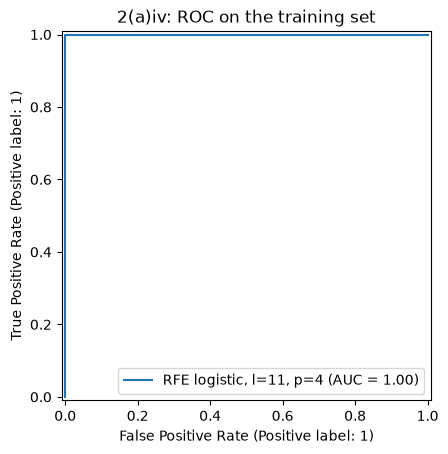

,beta,std_err,p_value
intercept,-13.2232,21.7791,0.5438
mean_5_part2,9.8470,25.9661,0.7045
mean_1_part7,-4.3127,19.5656,0.8255
max_3_part10,-4.6608,16.4645,0.7771
mean_5_part10,6.3906,20.1841,0.7515


In [11]:
def wald(model, Z, names):
    Xd = np.column_stack([np.ones(len(Z)), Z])
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    prob = model.predict_proba(Z)[:, 1]
    cov = np.linalg.pinv(Xd.T @ (Xd * (prob * (1 - prob))[:, None]))
    se = np.sqrt(np.diag(cov))
    return pd.DataFrame({"beta": beta, "std_err": se, "p_value": 2 * norm.sf(np.abs(beta / se))},
                        index=["intercept"] + list(names))


def binary_report(name, model, Z, y):
    pred, prob = model.predict(Z), model.predict_proba(Z)[:, 1]
    print(f"{name}: confusion [[TN, FP], [FN, TP]] = {confusion_matrix(y, pred).tolist()}, "
          f"accuracy {accuracy_score(y, pred):.4f}, AUC {roc_auc_score(y, prob):.3f}")
    return pred, prob


X_all = FEATURES[L_RFE].to_numpy()
scaler = StandardScaler().fit(X_all[train])
Z_all = scaler.transform(X_all)
keep = RFE(lr(), n_features_to_select=P_RFE, step=1).fit(Z_all[train], y_bin[train]).support_
names_rfe = FEATURES[L_RFE].columns[keep]
model_rfe = lr().fit(Z_all[train][:, keep], y_bin[train])
print("solver iterations used:", model_rfe.n_iter_[0], "of 1000")

_, prob_tr = binary_report("train", model_rfe, Z_all[train][:, keep], y_bin[train])
RocCurveDisplay.from_predictions(y_bin[train], prob_tr, name=f"RFE logistic, l={L_RFE}, p={P_RFE}")
plt.title("2(a)iv: ROC on the training set")
plt.show()
wald(model_rfe, Z_all[train][:, keep], names_rfe).round(4)

On the training set all 69 instances are classified correctly: the confusion matrix is [[60, 0], [0, 9]], accuracy and AUC are both 1.000, and the ROC curve goes straight to the top-left corner.

The table above has the coefficients (of standardized features) and their p-values. **These p-values can't be trusted.** They range from 0.54 to 0.83, so none of the four features looks significant, yet together they separate the training set perfectly. The cause is separation (see vi). The fitted probabilities are pushed almost exactly to 0 or 1, so $\hat p_i(1-\hat p_i)$ is almost 0 for every instance, the Fisher information is tiny, and the standard errors become huge.

The coefficients aren't maximum-likelihood estimates either: under separation no maximum exists (see vi), so their values depend on where the solver stopped. Their signs still say something: higher `mean_5` (avg_rss23) points toward bending, and higher `mean_1` (avg_rss12) and `max_3` (avg_rss13) point away from it.

#### v. Test Classifier

The test features are built with the same $l$, scaled with the training scaler, and reduced to the same features. Nothing is refit on the test set.

In [12]:
pred_te, _ = binary_report("test", model_rfe, Z_all[test][:, keep], y_bin[test])
print(f"CV accuracy {CV_RFE:.4f}")
print("misclassified:", names[test][pred_te != y_bin[test]].tolist())

test: confusion [[TN, FP], [FN, TP]] = [[15, 0], [1, 3]], accuracy 0.9474, AUC 0.867
CV accuracy 0.9846
misclassified: ['bending2/dataset2']


The test confusion matrix is [[15, 0], [1, 3]], so the test accuracy is 0.947 (18/19), against a CV accuracy of 0.985. The one error is `bending2/dataset2`, a bending instance classified as other.

The gap (3.8 points) is less than one test instance (1/19 = 5.3 points): one more correct test prediction would put the test accuracy above the CV accuracy. The CV accuracy is also a bit optimistic, since it's the best of all the (l, p) settings I tried.

#### vi. Separation

In [13]:
print("smallest |decision value| on the training set:",
      np.abs(model_rfe.decision_function(Z_all[train][:, keep])).min().round(3))
sep = {}
for l in range(1, 21):
    Z = StandardScaler().fit_transform(FEATURES[l].to_numpy()[train])
    sep[l] = accuracy_score(y_bin[train], lr().fit(Z, y_bin[train]).predict(Z))
print("training accuracy of logistic regression on all 18*l features, by l:", sep)

smallest |decision value| on the training set: 5.264
training accuracy of logistic regression on all 18*l features, by l: {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0, 8: 1.0, 9: 1.0, 10: 1.0, 11: 1.0, 12: 1.0, 13: 1.0, 14: 1.0, 15: 1.0, 16: 1.0, 17: 1.0, 18: 1.0, 19: 1.0, 20: 1.0}


**Yes, the classes are well separated.**

- With the 4 selected features, every training instance is classified correctly, and the one closest to the boundary is still 5.26 away on the log-odds scale (a predicted probability above 0.99 for its class).
- With all $18\,l$ features, logistic regression classifies the training set perfectly at every l from 1 to 20, so the two classes can be split exactly by a linear boundary.
- When the classes can be split exactly, the likelihood keeps increasing as the coefficients grow, so the maximum-likelihood estimate doesn't exist. That makes the coefficients and p-values in iv unstable. The fit in iv stopped after 13 iterations because it had reached the solver's stopping tolerance, which is the only reason the coefficients came out finite (footnote 5).

#### vii. Imbalance

For case-control sampling I keep all 9 bending instances (the cases), draw 9 of the 60 others at random (the controls), fit the same logistic regression on the same features, and then correct the intercept for the sampling:

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi},$$

where $\pi = 9/69$ is the bending fraction in the training set and $\tilde\pi = 9/18 = 1/2$ the fraction in the sample. Here the shift is $\log(9/60)$.

intercept shift log(9/60) = -1.897
train: confusion [[TN, FP], [FN, TP]] = [[60, 0], [0, 9]], accuracy 1.0000, AUC 1.000
test: confusion [[TN, FP], [FN, TP]] = [[15, 0], [1, 3]], accuracy 0.9474, AUC 0.817


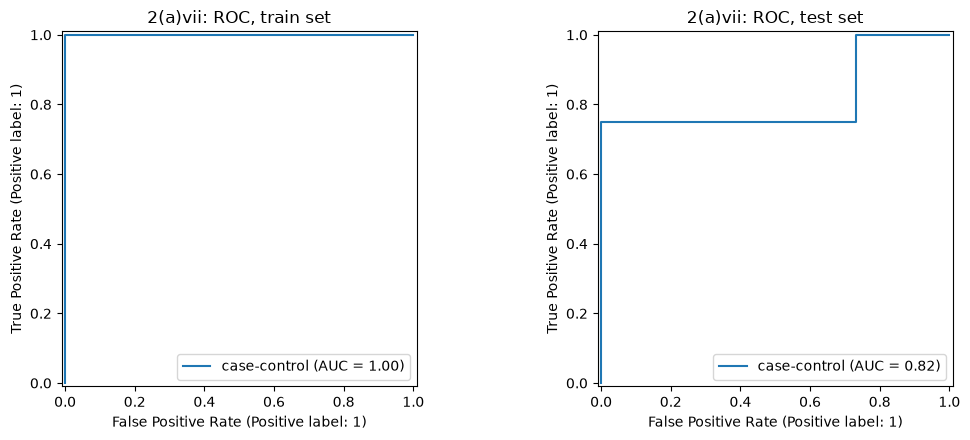

In [14]:
pos = np.where(train & (y_bin == 1))[0]
neg = np.where(train & (y_bin == 0))[0]
shift = np.log(len(pos) / len(neg))     # the balanced sample's log(1/2 / 1/2) term is 0

idx = np.r_[pos, np.random.default_rng(SEED).choice(neg, size=len(pos), replace=False)]
cc = lr().fit(Z_all[idx][:, keep], y_bin[idx])
cc.intercept_ = cc.intercept_ + shift
print(f"intercept shift log(9/60) = {shift:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, mask) in zip(axes, [("train", train), ("test", test)]):
    _, prob = binary_report(name, cc, Z_all[mask][:, keep], y_bin[mask])
    RocCurveDisplay.from_predictions(y_bin[mask], prob, name="case-control", ax=ax)
    ax.set_title(f"2(a)vii: ROC, {name} set")
plt.tight_layout()
plt.show()

**Yes, the classes are imbalanced.** The rows of the confusion matrices in iv and v add up to 60 other vs 9 bending (training) and 15 vs 4 (test). Bending is 13% of the training set, so a model that always predicts "other" would already get 87% training accuracy.

The case-control model classifies the training set perfectly and gets the same 18 of 19 test instances right as the full model in v, with a test AUC of 0.817.

- The intercept correction adds the same amount to every predicted log-odds, so it doesn't change how the instances are ranked, and it doesn't change the AUC. The test AUC is lower than the full model's (0.817 vs 0.867), most likely because the coefficients were estimated from 18 instances instead of 69.
- Case-control sampling doesn't improve anything here. It is useful when the majority class is very large: you fit on a small balanced sample and the intercept correction keeps the probabilities right. With 69 instances there is nothing to save.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Same features, folds and selection rule as 2(a)iii, with RFE replaced by an L1 penalty. The pair $(l, C)$ is chosen by 5-fold CV, where $C = 1/\lambda$ is the budget: a smaller $C$ means a stronger penalty and fewer features. Ties go to the smaller $l$, then the smaller $C$. The features are standardized (footnote 8) inside each training fold by putting the scaler and the model in one pipeline, and the solver is liblinear (footnote 9).

In [15]:
C_GRID = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]


def l1_logistic(C=1.0):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(l1_ratio=1, solver="liblinear", C=C, max_iter=1000, random_state=SEED))


def cv_grid(model, y, folds, c_grid):
    rows = []
    for l in range(1, 21):
        gs = GridSearchCV(model, {"logisticregression__C": c_grid}, cv=folds, scoring="accuracy")
        gs.fit(FEATURES[l].to_numpy()[train], y[train])
        rows += [(l, C, s) for C, s in zip(c_grid, gs.cv_results_["mean_test_score"])]
    return pd.DataFrame(rows, columns=["l", "C", "cv_acc"])


l1_cv = cv_grid(l1_logistic(), y_bin, folds_bin, C_GRID)
L_L1, C_L1, CV_L1 = best_row(l1_cv, "C")
print(f"best (l, C) = ({L_L1}, {C_L1:g}), CV accuracy {CV_L1:.4f}\n")
print("CV accuracy by l (rows) and C (columns):")
print(l1_cv.pivot(index="l", columns="C", values="cv_acc").round(3).to_string())

best (l, C) = (19, 3), CV accuracy 0.9846

CV accuracy by l (rows) and C (columns):
C   0.01    0.03    0.10    0.30    1.00    3.00    10.00   30.00   100.00
l                                                                         
1     0.87    0.87   0.900   0.942   0.942   0.970   0.970   0.970   0.970
2     0.87    0.87   0.870   0.926   0.926   0.926   0.926   0.926   0.926
3     0.87    0.87   0.870   0.970   0.956   0.956   0.942   0.942   0.927
4     0.87    0.87   0.885   0.927   0.942   0.942   0.942   0.942   0.942
5     0.87    0.87   0.885   0.927   0.913   0.913   0.913   0.927   0.927
6     0.87    0.87   0.885   0.927   0.899   0.899   0.927   0.927   0.913
7     0.87    0.87   0.885   0.913   0.899   0.899   0.913   0.899   0.899
8     0.87    0.87   0.885   0.913   0.899   0.899   0.913   0.927   0.913
9     0.87    0.87   0.885   0.913   0.913   0.913   0.956   0.927   0.927
10    0.87    0.87   0.885   0.913   0.913   0.913   0.913   0.913   0.927
11    0.87    0.

In [16]:
model_l1 = l1_logistic(C_L1).fit(FEATURES[L_L1].to_numpy()[train], y_bin[train])
coef = pd.Series(model_l1[-1].coef_.ravel(), index=FEATURES[L_L1].columns)
print(f"non-zero coefficients: {(coef != 0).sum()} of {len(coef)}")
print(coef[coef != 0].sort_values(key=abs, ascending=False).round(3).to_string(), "\n")
binary_report("train", model_l1, FEATURES[L_L1].to_numpy()[train], y_bin[train])
pred, _ = binary_report("test", model_l1, FEATURES[L_L1].to_numpy()[test], y_bin[test])
print("misclassified test instances:", names[test][pred != y_bin[test]].tolist())

non-zero coefficients: 11 of 342
mean_5_part3     2.941
max_1_part11    -0.826
std_5_part18    -0.574
std_4_part14    -0.443
mean_5_part17    0.392
std_6_part15    -0.353
std_3_part5      0.291
std_5_part19     0.164
max_6_part18    -0.102
std_5_part15    -0.021
mean_5_part6     0.016 

train: confusion [[TN, FP], [FN, TP]] = [[60, 0], [0, 9]], accuracy 1.0000, AUC 1.000
test: confusion [[TN, FP], [FN, TP]] = [[15, 0], [1, 3]], accuracy 0.9474, AUC 0.833
misclassified test instances: ['bending2/dataset2']


CV picks **(l, C) = (19, 3)**, with accuracy 0.985, the same as RFE in 2(a)iii. The peak is narrow again: the next-best settings reach 0.970, one held-out instance fewer.

The final model keeps 11 of its 342 features. It is perfect on the training set ([[60, 0], [0, 9]], AUC 1.000). On the test set it gets 18/19 right (accuracy 0.947, AUC 0.833) and misses the same instance as the RFE model, `bending2/dataset2`. The largest coefficient by far is `mean_5_part3` (+2.94): as in 2(a), a higher mean of series 5 (avg_rss23) points toward bending.

#### ii. Comparison

- Neither performs better here. Both reach CV accuracy 0.985 and 18/19 on the test set, and both miss the same instance. The test AUCs differ (0.833 for L1, 0.867 for RFE), but with 4 bending and 15 other test instances there are only 60 bending/other pairs, and the difference is 2 of those pairs ranked differently.
- L1 is easier to implement. Feature selection and fitting happen in one fit with one tuning parameter, and `GridSearchCV` handles the folds. RFE needs an elimination loop inside every fold plus a search over p. p-value pruning doesn't work at all here, because separation makes the p-values meaningless.
- L1 also avoids the problem in 2(a)vi. The penalty keeps the coefficients finite even though the classes are separable, so the model doesn't depend on where the solver happens to stop.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

This follows 2(b)i, with the 7-class folds: (l, C) is chosen by 5-fold CV, with ties going to the smaller l and then the smaller C. scikit-learn fits the multinomial model with the saga solver, which supports the L1 penalty (footnote 10). saga shuffles the data, so `random_state` is fixed to make the result reproducible.

The C grid is the 2(b)i grid plus one larger value, C = 1000. If the best C lands at the top of the 2(b) grid, the extra value shows whether a weaker penalty would do even better.

In [17]:
C_GRID_MN = C_GRID + [1000]     # one value past the 2(b) grid, to check that accuracy has leveled off


def l1_multinomial(C=1.0):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(l1_ratio=1, solver="saga", C=C, max_iter=5000, tol=1e-3, random_state=SEED))


mn_cv = cv_grid(l1_multinomial(), y_multi, folds_multi, C_GRID_MN)
L_MN, C_MN, CV_MN = best_row(mn_cv, "C")
print(f"best (l, C) = ({L_MN}, {C_MN:g}), CV accuracy {CV_MN:.4f}\n")
print("CV accuracy by l (rows) and C (columns):")
print(mn_cv.pivot(index="l", columns="C", values="cv_acc").round(3).to_string())

best (l, C) = (6, 100), CV accuracy 0.8846

CV accuracy by l (rows) and C (columns):
C   0.01     0.03     0.10     0.30     1.00     3.00     10.00    30.00    100.00   1000.00
l                                                                                           
1     0.174    0.159    0.622    0.841    0.841    0.826    0.826    0.826    0.826    0.812
2     0.174    0.159    0.651    0.798    0.798    0.812    0.841    0.869    0.869    0.884
3     0.174    0.174    0.579    0.842    0.812    0.827    0.856    0.856    0.856    0.856
4     0.174    0.174    0.579    0.768    0.812    0.855    0.854    0.840    0.825    0.825
5     0.174    0.174    0.565    0.741    0.785    0.813    0.842    0.870    0.870    0.870
6     0.174    0.174    0.549    0.725    0.768    0.798    0.812    0.842    0.885    0.885
7     0.174    0.174    0.535    0.726    0.769    0.785    0.842    0.826    0.827    0.827
8     0.174    0.174    0.493    0.784    0.768    0.768    0.797    0.825    

With 7 classes the confusion matrix is $7 \times 7$, with the true activity in the rows, the predicted activity in the columns and the correct predictions on the diagonal. ROC is only defined for two classes, so I draw one curve per activity: that activity is the positive class, the other six are negative (one-vs-rest), and the score is the predicted probability of that activity. The macro AUC is the average of the seven one-vs-rest AUCs.

L1 multinomial (l=6, C=100): test error 0.1053 (2/19 wrong), macro one-vs-rest AUC 0.979
misclassified: ['bending2/dataset2 -> sitting', 'standing/dataset1 -> sitting']


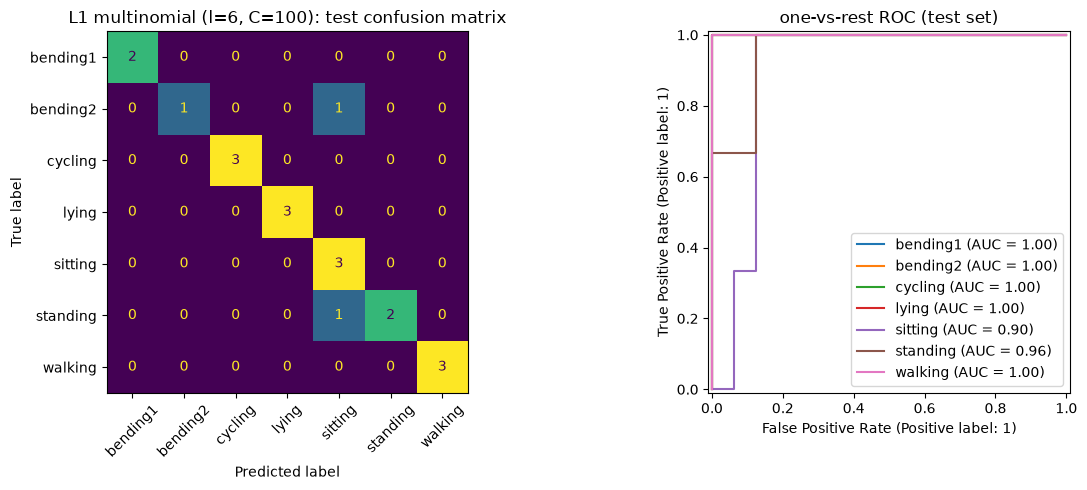

non-zero coefficients: 684 of 756


In [18]:
def evaluate_multiclass(model, l, title):
    X = FEATURES[l].to_numpy()
    model.fit(X[train], y_multi[train])
    pred, prob = model.predict(X[test]), model.predict_proba(X[test])
    err = 1 - accuracy_score(y_multi[test], pred)
    auc = roc_auc_score(y_multi[test], prob, multi_class="ovr", average="macro", labels=model.classes_)
    print(f"{title}: test error {err:.4f} ({int((pred != y_multi[test]).sum())}/{test.sum()} wrong), "
          f"macro one-vs-rest AUC {auc:.3f}")
    wrong = pred != y_multi[test]
    print("misclassified:", [f"{n} -> {p}" for n, p in zip(names[test][wrong], pred[wrong])])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay.from_predictions(y_multi[test], pred, labels=ACTIVITIES, ax=axes[0],
                                            xticks_rotation=45, colorbar=False)
    for k, c in enumerate(model.classes_):
        RocCurveDisplay.from_predictions(y_multi[test] == c, prob[:, k], name=c, ax=axes[1])
    axes[0].set_title(f"{title}: test confusion matrix")
    axes[1].set_title("one-vs-rest ROC (test set)")
    plt.tight_layout()
    plt.show()


model_mn = l1_multinomial(C_MN)
evaluate_multiclass(model_mn, L_MN, f"L1 multinomial (l={L_MN}, C={C_MN:g})")
print(f"non-zero coefficients: {(model_mn[-1].coef_ != 0).sum()} of {model_mn[-1].coef_.size}")

CV picks (l, C) = (6, 100), with accuracy 0.885. C = 1000 ties it at l = 6 and doesn't beat 0.885 at any other l, so the accuracy has leveled off and the tie-break keeps C = 100.

**Test error: 2/19 = 0.105** (macro one-vs-rest AUC 0.979). Both errors are predicted as sitting: `bending2/dataset2` and `standing/dataset1`. Every test instance of the other five activities is correct.

The selected penalty is weak: the model keeps 684 of its 756 coefficients. CV accuracy goes up as the penalty gets weaker, so in the 7-class problem the L1 penalty doesn't do much feature selection.

#### ii. Naive Bayes

- Gaussian NB models each feature within each class as a normal distribution, so it uses the continuous features directly. Only $l$ is chosen by CV.
- Multinomial NB models counts (e.g. word counts). Means, SDs and maxima aren't counts, so I discretize first: each feature is cut into equal-width bins, the bin it falls in is one-hot encoded, and those indicators are the counts. The bin edges are learned inside each training fold (the discretizer is part of the pipeline). $l$ and the number of bins (3, 5 or 10) are chosen by CV. For reference, the table also shows Multinomial NB on the raw feature values (all features are non-negative, so it runs).

In [19]:
nb_rows = []
for l in range(1, 21):
    X = FEATURES[l].to_numpy()[train]
    nb_rows.append(("Gaussian", l, None, cross_val_score(GaussianNB(), X, y_multi[train], cv=folds_multi).mean()))
    nb_rows.append(("Multinomial, raw values", l, None,
                    cross_val_score(MultinomialNB(), X, y_multi[train], cv=folds_multi).mean()))
    for bins in (3, 5, 10):
        est = make_pipeline(KBinsDiscretizer(n_bins=bins, encode="onehot", strategy="uniform"), MultinomialNB())
        nb_rows.append(("Multinomial, binned", l, bins, cross_val_score(est, X, y_multi[train], cv=folds_multi).mean()))
nb_cv = pd.DataFrame(nb_rows, columns=["model", "l", "bins", "cv_acc"])
nb_best = pd.DataFrame([best_row(g, "bins") for _, g in nb_cv.groupby("model")]).set_index("model")
print(nb_best.round(4).to_string())

                          l  bins  cv_acc
model                                    
Gaussian                  1   NaN  0.8846
Multinomial, binned       5   5.0  0.8989
Multinomial, raw values  11   NaN  0.8560


Gaussian NB (l=1): test error 0.1053 (2/19 wrong), macro one-vs-rest AUC 0.997
misclassified: ['bending2/dataset1 -> sitting', 'standing/dataset1 -> sitting']


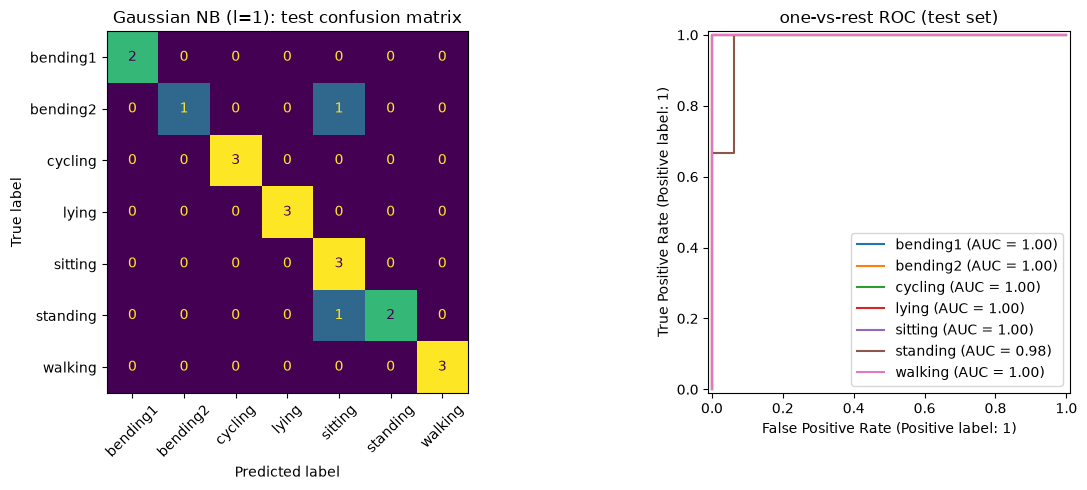

Multinomial NB, 5 bins (l=5): test error 0.1579 (3/19 wrong), macro one-vs-rest AUC 0.991
misclassified: ['bending2/dataset2 -> sitting', 'sitting/dataset1 -> standing', 'standing/dataset1 -> sitting']


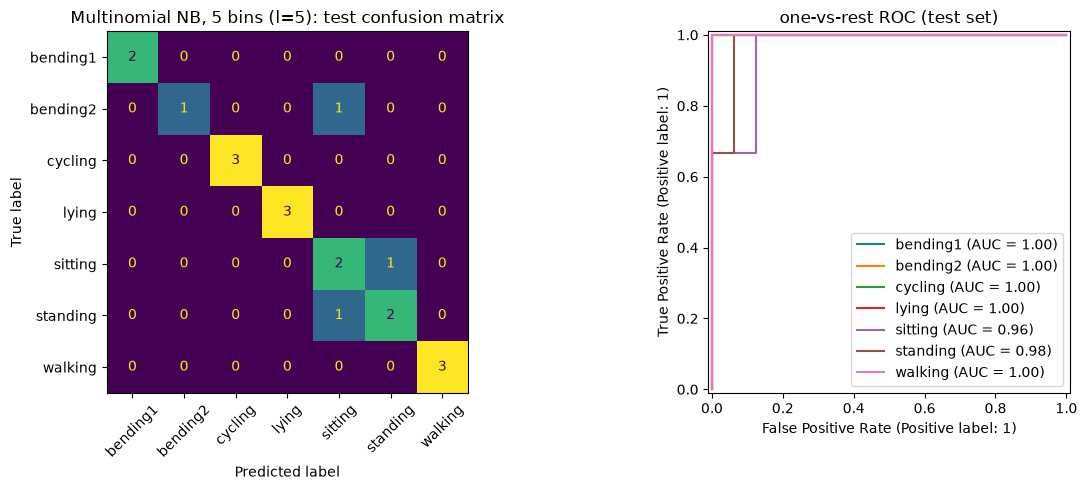

In [20]:
L_GNB = int(nb_best.loc["Gaussian", "l"])
L_MNB, BINS = int(nb_best.loc["Multinomial, binned", "l"]), int(nb_best.loc["Multinomial, binned", "bins"])
evaluate_multiclass(GaussianNB(), L_GNB, f"Gaussian NB (l={L_GNB})")
evaluate_multiclass(make_pipeline(KBinsDiscretizer(n_bins=BINS, encode="onehot", strategy="uniform"), MultinomialNB()),
                    L_MNB, f"Multinomial NB, {BINS} bins (l={L_MNB})")

- Gaussian NB (l = 1) and binned Multinomial NB (l = 5, 5 bins) are one held-out instance apart in CV (0.885 vs 0.899) and one test instance apart (2 vs 3 of 19 wrong), in opposite directions, so neither is clearly better.
- Both mistake one bending2 instance and `standing/dataset1` for sitting. Multinomial NB also mistakes `sitting/dataset1` for standing.
- Binning matters for Multinomial NB. On the raw values its best CV accuracy is 0.856, below both of these. Raw values treat a mean of 40 as "40 counts", which isn't what the model assumes. Binning gives it count-like inputs, at the cost of treating every value in a bin as the same, which is why the number of bins is tuned.

#### iii. Comparison

| Model | Selected setting | CV accuracy | Test error | Macro AUC (test) |
| --- | --- | --- | --- | --- |
| L1 multinomial regression | l = 6, C = 100 | 0.885 | 0.105 (2/19) | 0.979 |
| Gaussian NB | l = 1 | 0.885 | 0.105 (2/19) | 0.997 |
| Multinomial NB, 5 bins | l = 5 | 0.899 | 0.158 (3/19) | 0.991 |

**Gaussian Naive Bayes, by a small margin.** It ties L1 multinomial regression on CV accuracy and test error, ranks the test instances slightly better (macro AUC 0.997), and is much simpler: no penalty to tune, no iterative solver, and it uses the 18 whole-series features (l = 1) instead of 108. Binned Multinomial NB has the best CV accuracy but one more test error.

All these differences are one or two instances, so the three methods perform about the same on this data, and Gaussian NB needs the least work to get there. They also fail in the same place: every error is a bending2, standing or sitting instance predicted as sitting or standing.

## 3. ISLR 4.8.3

If at least two classes have different variances, the Bayes classifier is quadratic in $x$, not linear. (If all the $\sigma_k^2$ are equal, this is LDA and the boundary is linear.)

Step 1: Bayes classifier. With prior $\pi_k$ and $X \mid Y = k \sim N(\mu_k, \sigma_k^2)$, the Bayes classifier assigns $x$ to the class with the largest posterior

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every class, so this is the class with the largest $\pi_k f_k(x)$, or equivalently the largest $\log\big(\pi_k f_k(x)\big)$.

Step 2: discriminant. Taking logs,

$$\log\big(\pi_k f_k(x)\big) = \log \pi_k - \tfrac{1}{2}\log(2\pi) - \log \sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Drop $-\tfrac12 \log(2\pi)$, which is the same for every class, and expand the square:

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k .$$

In Section 4.4.1 all classes share one $\sigma^2$, so $-x^2/(2\sigma^2)$ and $-\log\sigma$ are the same for every class and can be dropped, which leaves a discriminant that is linear in $x$. Here the coefficient of $x^2$, $-1/(2\sigma_k^2)$, changes with $k$, so it cannot be dropped: $\delta_k(x)$ is a quadratic function of $x$.

Step 3: decision boundary. The boundary between classes $j$ and $k$ is where $\delta_j(x) = \delta_k(x)$:

$$\left(\frac{1}{2\sigma_k^2} - \frac{1}{2\sigma_j^2}\right) x^2 + \left(\frac{\mu_j}{\sigma_j^2} - \frac{\mu_k}{\sigma_k^2}\right) x + \left(\frac{\mu_k^2}{2\sigma_k^2} - \frac{\mu_j^2}{2\sigma_j^2} + \log\frac{\pi_j\, \sigma_k}{\pi_k\, \sigma_j}\right) = 0 .$$

If $\sigma_j^2 \neq \sigma_k^2$, the $x^2$ coefficient is not zero, so this is a quadratic equation with up to two roots.

Step 4: why this is not linear. With one feature, a linear classifier is a single threshold: one class on each side of one point. A quadratic boundary can have two. For example, take two classes with $\pi_1 = \pi_2$, $\mu_1 = \mu_2 = 0$, $\sigma_1 = 1$ and $\sigma_2 = 2$. Then

$$\delta_1(x) - \delta_2(x) = -\frac{x^2}{2} + \frac{x^2}{8} - \log 1 + \log 2 = \log 2 - \frac{3x^2}{8},$$

so class 1 is chosen exactly when $|x| < \sqrt{8 \log 2 / 3} \approx 1.36$. Class 1 wins on a middle interval and loses on both tails, which no single threshold can produce. So the Bayes classifier is not linear; it is quadratic. When all variances are equal, the $x^2$ terms cancel and the boundary is linear again (LDA).

## 4. ISLR 4.8.7

Given: $\mu_{Yes} = 10$, $\mu_{No} = 0$, common variance $\sigma^2 = 36$ ($\sigma = 6$), $P(Yes) = 0.8$, $P(No) = 0.2$, and $x = 4$.

Step 1: normal densities at $x = 4$.

$$f_{Yes}(4) = \frac{1}{\sqrt{2\pi \cdot 36}}\, e^{-(4-10)^2/72} = \frac{e^{-1/2}}{6\sqrt{2\pi}} \approx 0.04033, \qquad f_{No}(4) = \frac{1}{\sqrt{2\pi \cdot 36}}\, e^{-(4-0)^2/72} = \frac{e^{-2/9}}{6\sqrt{2\pi}} \approx 0.05324 .$$

Step 2: Bayes' theorem. The common factor $1/(6\sqrt{2\pi})$ cancels:

$$P(Yes \mid X=4) = \frac{0.8\, f_{Yes}(4)}{0.8\, f_{Yes}(4) + 0.2\, f_{No}(4)} = \frac{0.8\, e^{-1/2}}{0.8\, e^{-1/2} + 0.2\, e^{-2/9}} = \frac{0.48522}{0.48522 + 0.16015} \approx 0.7519 .$$

**Answer:** the probability that the company issues a dividend this year is 0.7519 (75.19%). The cell below checks the arithmetic.

$x = 4$ is closer to the "No" mean than to the "Yes" mean, so the density alone slightly favors "No" (0.0532 vs 0.0403). The 80% prior is what pushes the posterior up to 75%.

In [21]:
f_yes, f_no = norm.pdf(4, 10, 6), norm.pdf(4, 0, 6)
print(f"f_Yes(4) = {f_yes:.5f}, f_No(4) = {f_no:.5f}, "
      f"P(Yes | X = 4) = {0.8 * f_yes / (0.8 * f_yes + 0.2 * f_no):.4f}")

f_Yes(4) = 0.04033, f_No(4) = 0.05324, P(Yes | X = 4) = 0.7519


## 5.1. Extra Practice ISLR 4.8.4

Extra practice, not submitted.

## 5.2. Extra Practice ISLR 4.8.9

Extra practice, not submitted.

## References

- https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- https://scikit-learn.org/stable/modules/naive_bayes.html
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html
- https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html

*AI use: Claude Code (Anthropic) was used to edit this notebook from my own script and notes*